In [1]:
import ensaio
import xarray as xr
import numpy as np
import scipy as sp
import harmonica as hm
import verde as vd
import numba
import choclo.constants
import matplotlib.pyplot as plt
import matplotlib.patches

import sys
sys.path.append("..")
import micromag as mg
import multipoles as mt

## Read data using ensaio

In [2]:
path_data = ensaio.fetch_morroco_speleothem_qdm(file_format="matlab", version=1)
data = mg.load_qdm(path_data)

In [3]:
height_difference = 5
data = (
    hm.upward_continuation(data.bz, height_difference)
    .assign_attrs(data.bz.attrs)
    .to_dataset(name="bz")
    .assign_coords(x=data.x, y=data.y)
    .assign_coords(z=data.z + height_difference)
)

data = data.assign(mg.data_gradients(data.bz))

Text(1455, 890, 'selected source')

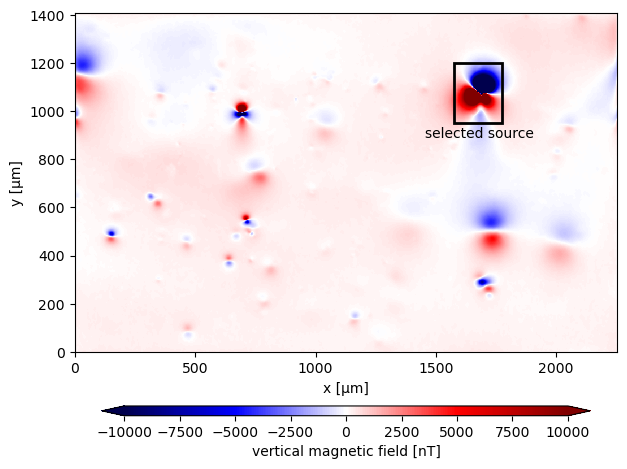

In [4]:
fig, axes = plt.subplots(1, 1, figsize=(7, 7))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
scale = 10000
data.bz.plot.pcolormesh(vmin=-scale, vmax=scale, cmap='seismic',  cbar_kwargs=cbar_kwargs)
axes.set_aspect("equal")


# define window for the selected anomaly
window = [1575, 1775, 950, 1200]

rect = matplotlib.patches.Rectangle(
    xy=[window[0], window[2]],
    width=window[1] - window[0],
    height=window[3] - window[2],
    edgecolor="k",
    fill=False,
    linewidth=2,
)
axes.add_patch(rect)

axes.text(window[0]-120, window[2]-60, 'selected source')

## Select anomaly

In [5]:
data_anomaly = data.sel(x=slice(*window[:2]), y=slice(*window[2:]))

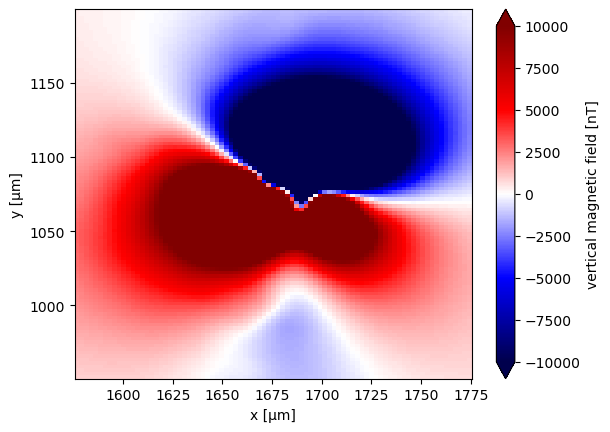

In [6]:
data_anomaly.bz.plot.pcolormesh(cmap="seismic", vmax=scale, vmin=-scale)

## Non-linear dipole fitting

In [7]:
def goal_function_dipole(parameter, obs_data, coordinates, amplitude, x_0, y_0, z_0):
    bz = mg.dipole_bz(coordinates, 
                      ([parameter[0]*x_0], [parameter[1]*y_0], [parameter[2]*z_0]),
                     np.array([parameter[3], parameter[4], parameter[5]])*amplitude
                     )
    
    Res = np.linalg.norm(obs_data-bz.ravel())
    return(Res)

In [8]:
%%time

position, base_level = mg.euler_deconvolution(
        data_anomaly.bz, 
        data_anomaly.x_deriv, 
        data_anomaly.y_deriv, 
        data_anomaly.z_deriv,
    )

data_minus_background = data_anomaly.bz.values - base_level
data_anomaly = data_anomaly.assign(data_minus_background=(['y','x'], data_minus_background))
data_anomaly.data_minus_background.attrs = {"long_name": "dipole-model", "units": "nT"}

moment, covariance, r2, SNR = mg.dipole_moment_inversion(
    data_anomaly.data_minus_background, position,
)

anomaly_table=vd.grid_to_table(data_anomaly)
amplitude = np.linalg.norm(moment)

## SCIPY MINIMIZATION DIPOLE
args_dip=(anomaly_table.bz.ravel(), 
     ( anomaly_table.x.values,
       anomaly_table.y.values, 
       anomaly_table.z.values.ravel()),
       amplitude, position[0], position[1], position[2])

minimization=sp.optimize.minimize(goal_function_dipole, (1, 1, 1,
                                                  moment[0]/amplitude,
                                                  moment[1]/amplitude,
                                                  moment[2]/amplitude),
                                  args=args_dip,
                                  method='Nelder-Mead', options=dict(maxiter=1000))

# print(minimization.x[0])
if minimization.success:
    
    moment = np.array([minimization['x'][3], minimization['x'][4], minimization['x'][5]])*amplitude
    position = np.array([minimization['x'][0]*position[0], 
                         minimization['x'][1]*position[1],
                         minimization['x'][2]*position[2]])
    xxx, yyy = np.meshgrid(data_anomaly.x.values, data_anomaly.y.values)
    zzz = anomaly_table.z.values.ravel()
    pred = mg.dipole_bz([xxx, yyy, zzz], 
              position,
              moment
             )
    
    residuals = data_minus_background.ravel() - pred.ravel()
    residuals_sum_sq = np.sum(residuals**2)
    r2 = 1 - residuals_sum_sq / np.linalg.norm(data_minus_background.ravel() - np.mean(data_minus_background.ravel())) ** 2

# r2_dipole = r2
print("Non-linear dipole moment (Inc, Dec, m): ", mg.vector_to_angles(moment))


Non-linear dipole moment (Inc, Dec, m):  (20.88521637843539, -147.47757368571902, 4.659836097625526e-11)
CPU times: user 2.97 s, sys: 2.45 s, total: 5.42 s
Wall time: 1.32 s


In [9]:
data_anomaly = data_anomaly.assign(dipole_nonlinear=(['y','x'], pred))
data_anomaly = data_anomaly.assign(residual_dipole=(['y','x'], data_anomaly.bz.values - data_anomaly.dipole_nonlinear.values))

data_anomaly.dipole_nonlinear.attrs = {"long_name": "dipole-model", "units": "nT"}
data_anomaly.residual_dipole.attrs = {"long_name": "residual-dipole-model", "units": "nT"}


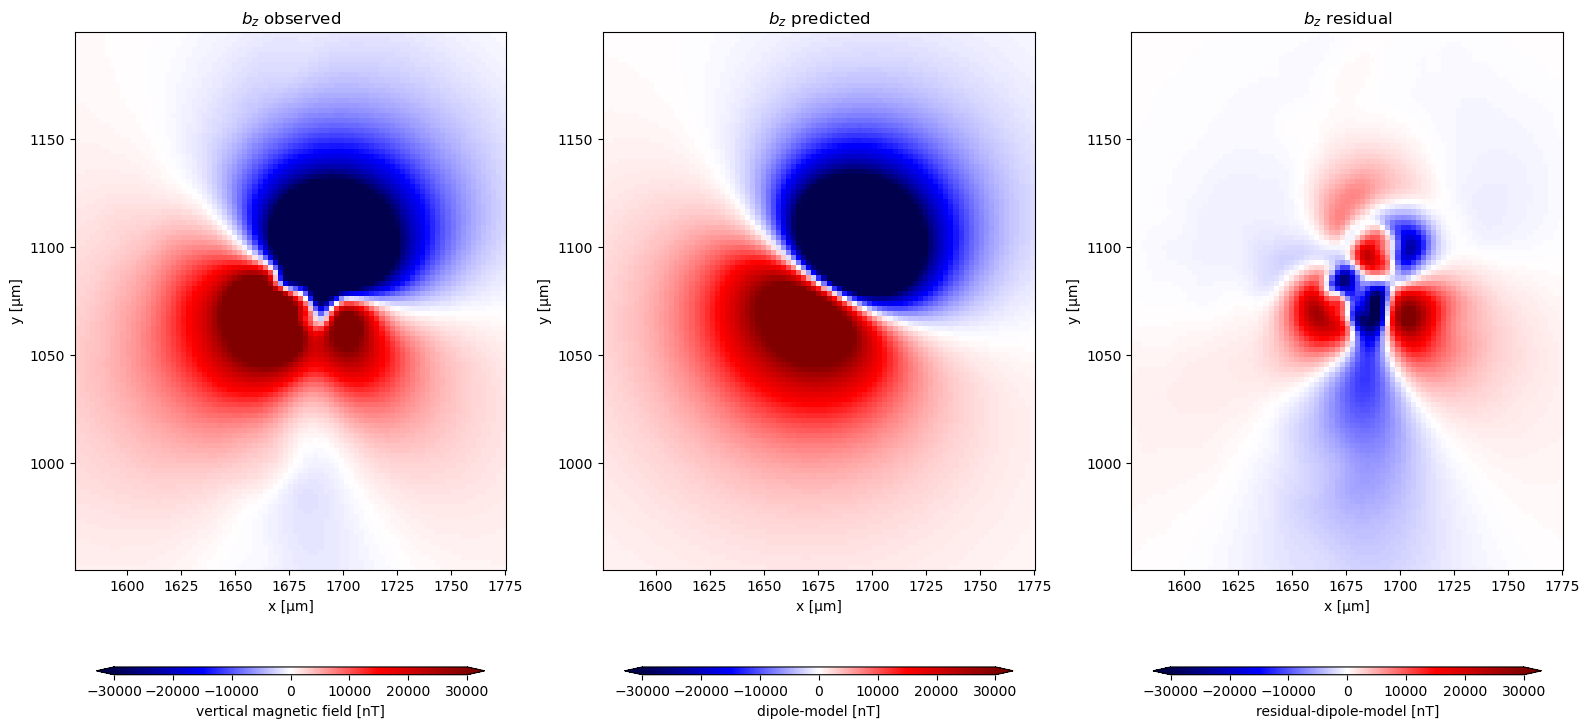

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
vmax =  30000
vmin = -30000 #data['bz_total'].values.min()
for field, ax in zip(["bz", "dipole_nonlinear", "residual_dipole"], axes.ravel()):

    data_anomaly[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()

## Spherical Harmonic fitting

In [11]:
coordinates = (anomaly_table.x, anomaly_table.y, anomaly_table.z)
euler = hm.EulerDeconvolution(structural_index=3).fit(coordinates, 
                                                      (anomaly_table.bz, 
                                                       anomaly_table.x_deriv, 
                                                       anomaly_table.y_deriv, 
                                                       anomaly_table.z_deriv))
euler.location_, euler.base_level_

(array([1685.45426247, 1084.39765454,  -20.16898198]), -98.618857705216)

In [12]:
%time
location =  euler.location_.copy()

sph = mt.SphericalHarmonicsBz(location, damping=1e-1, min_degree=1, max_degree=10).fit(coordinates, anomaly_table.bz)
sph.update_location(coordinates, anomaly_table)


print("Spherical moment (Inc, Dec, m): ", mg.vector_to_angles(sph.magnetic_moment_))


CPU times: user 29 µs, sys: 18 µs, total: 47 µs
Wall time: 7.39 µs
Spherical moment (Inc, Dec, m):  (24.844829395984544, -142.45903189922097, 4.104076865237194e-11)


In [13]:
pred_sph = sph.predict(coordinates).reshape(data_anomaly.bz.shape)

data_anomaly = data_anomaly.assign(spherical_harmonic=(['y','x'], pred_sph))
data_anomaly = data_anomaly.assign(residual_spherical=(['y','x'], data_anomaly.bz.values - data_anomaly.spherical_harmonic.values))

data_anomaly.spherical_harmonic.attrs = {"long_name": "spherical-model", "units": "nT"}
data_anomaly.residual_spherical.attrs = {"long_name": "residual-spherical", "units": "nT"}



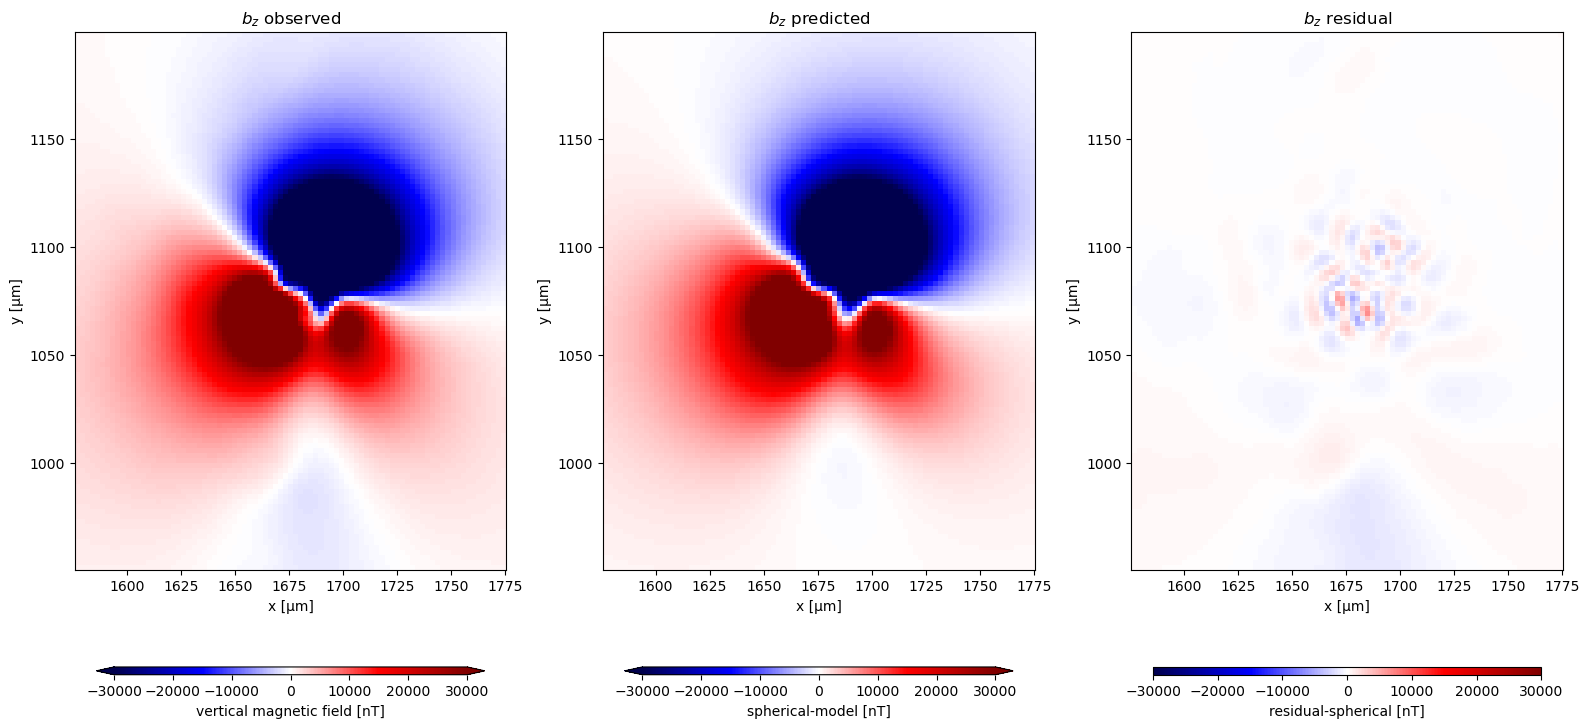

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
vmax =  30000
vmin = -30000 #data['bz_total'].values.min()
for field, ax in zip(["bz", "spherical_harmonic", "residual_spherical"], axes.ravel()):

    data_anomaly[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()